# 01. Exploring the cut-off scores

A first look at the dataset: what is in it, how cut-offs are distributed, and how they moved between years. Every number below is computed from `data/`, so re-running the notebook after new data is added updates it.

*Khám phá dữ liệu điểm chuẩn: dữ liệu gồm gì, phân bố điểm chuẩn, và thay đổi qua các năm. Có thể dùng làm điểm xuất phát cho đồ án phân tích dữ liệu.*

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from diem_chuan import load_scores, load_universities

df = load_scores()
names = load_universities().set_index('code')['short_name']
df['uni'] = df['university'].map(names)
print(f'{len(df):,} rows, {df.university.nunique()} universities, '
      f'{df.year.min()}-{df.year.max()}')
df.head()

1,088 rows, 3 universities, 2021-2026


,university,year,major_code,major_name,method,subject_groups,score,scale,source,note,uni
0,BKA,2023,BF1,Kỹ thuật Sinh học,thpt,A00 B00 D07,24.60,30.0,bka-2023,,HUST
1,BKA,2023,BF2,Kỹ thuật Thực phẩm,thpt,A00 B00 D07,24.49,30.0,bka-2023,,HUST
2,BKA,2023,BF-E12,Kỹ thuật Thực phẩm (CT tiên tiến),thpt,A00 B00 D07,22.70,30.0,bka-2023,,HUST
3,BKA,2023,BF-E19,Kỹ thuật sinh học (CT tiên tiến),thpt,A00 B00 D07,21.00,30.0,bka-2023,,HUST
4,BKA,2023,CH1,Kỹ thuật Hóa học,thpt,A00 B00 D07,23.70,30.0,bka-2023,,HUST


## What is in the data

Rows per university, year and method. Methods differ between universities and years, which is why every comparison below stays within one method and one scale.

In [2]:
df.pivot_table(index=['uni', 'method', 'scale'], columns='year', values='score',
               aggfunc='size', fill_value=0)

year                        2021  2022  2023  2024  2025  2026
uni  method         scale                                     
HUST thpt           30.0       0     0    63    64    65    68
     tsa            100.0      0     0    61    64    65    68
     xttn_chung_chi 100.0      0     0     0     0    65    68
     xttn_ho_so     100.0      0     0     0     0    65    68
NEU  thpt           30.0       0     0     0     0    73    88
UIT  dgnl_hcm       1200.0    11    12    12    13    14     0
     thpt           30.0      11    12    12    13    14     0
     xt_tong_hop    100.0      0     0     0     0     0    19

## Distribution of exam-score cut-offs (30-point scale)

Latest year of each university, method `thpt`.

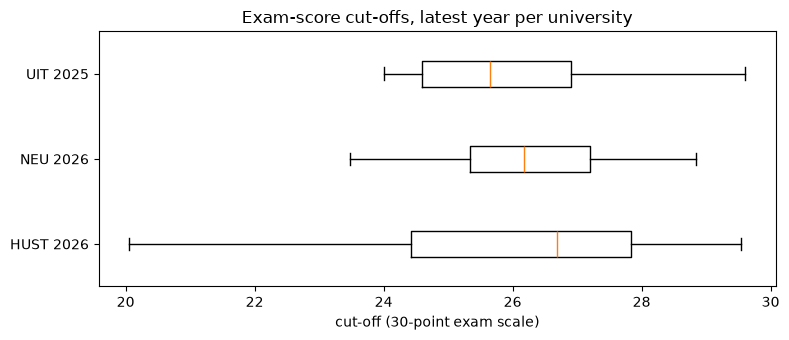

,count,min,50%,max
uni,,,,
HUST,68.0,20.06,26.685,29.54
NEU,88.0,23.48,26.170,28.84
UIT,14.0,24.00,25.650,29.60


In [3]:
thpt = df[(df.method == 'thpt') & (df.scale == 30)]
latest = thpt[thpt.year == thpt.groupby('university').year.transform('max')]

fig, ax = plt.subplots(figsize=(8, 3.5))
groups = [g.score.values for _, g in latest.groupby('uni')]
labels = [f'{u} {y}' for u, y in latest.groupby('uni').year.max().items()]
ax.boxplot(groups, orientation='horizontal')
ax.set_yticks(range(1, len(labels) + 1), labels)
ax.set_xlabel('cut-off (30-point exam scale)')
ax.set_title('Exam-score cut-offs, latest year per university')
plt.tight_layout()
plt.show()

latest.groupby('uni').score.describe()[['count', 'min', '50%', 'max']]

## Biggest changes from one year to the next

Programmes with an exam-score cut-off in both of a university's two latest years.

In [4]:
def year_on_year(rows: pd.DataFrame) -> pd.DataFrame:
    per_year = rows.groupby(['uni', 'major_code', 'year']).score.min().unstack('year')
    out = []
    for uni, block in per_year.groupby(level='uni'):
        years = sorted(block.dropna(axis=1, how='all').columns)[-2:]
        if len(years) < 2:
            continue
        pair = block[years].dropna()
        out.append(pair.assign(change=pair[years[1]] - pair[years[0]],
                               years=f'{years[0]}->{years[1]}')[['years', 'change']])
    return pd.concat(out)

changes = year_on_year(thpt)
print(changes.groupby('uni').change.describe()[['count', 'mean', 'min', 'max']].round(2))
changes.sort_values('change').iloc[list(range(3)) + list(range(-3, 0))]

      count  mean   min   max
uni                          
HUST   61.0  0.64 -3.55  3.14
NEU    70.0  0.20 -1.67  1.05
UIT    13.0 -0.65 -1.70  1.30


year                  years  change
uni  major_code                    
HUST FL2         2025->2026   -3.55
UIT  7480102     2024->2025   -1.70
NEU  CLC2        2025->2026   -1.67
HUST CH2         2025->2026    1.75
     MS-E3       2025->2026    1.99
     TROY-IT     2025->2026    3.14

## One programme family over six years: UIT

UIT published exam-score cut-offs for 2021-2025, then moved to a single 100-point combined score in 2026. The 2026 values are on a different scale and are left out here.

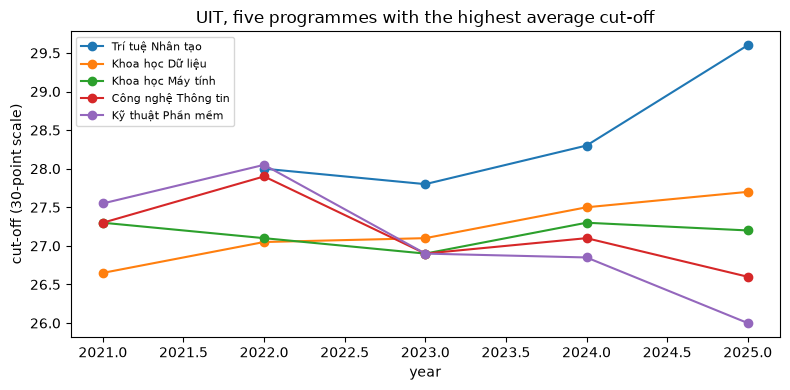

In [5]:
uit = thpt[thpt.university == 'QSC']
wide = uit.pivot_table(index='year', columns='major_name', values='score')
top = wide.mean().sort_values(ascending=False).index[:5]
ax = wide[top].plot(marker='o', figsize=(8, 4))
ax.set_ylabel('cut-off (30-point scale)')
ax.set_title('UIT, five programmes with the highest average cut-off')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Ideas for further analysis

- Compare engineering and economics programmes once more universities are in the data.
- Link programme codes that change between years (issue on GitHub) and redo the year-on-year table.
- Relate cut-offs to the national score distribution of each subject group.

*Gợi ý hướng phân tích tiếp cho đồ án: so sánh khối kỹ thuật và kinh tế, nối các mã ngành đổi tên qua các năm, đối chiếu với phổ điểm thi THPT.*